# Formula 1 Podium Prediction — Milestone 1

**Task:** for every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`)
using only information known **after qualifying and before the race starts**.

**Team:

| # | Section | Owner |
|---|---|---|
| 0 | Setup & shared config | |
| 1 | Load raw data | |
| 2 | EDA before cleaning | |
| 3 | Cleaning: sentinels & semantic typing | |
| 4 | Key audit: primary & foreign keys | |
| 5 | Grain: one row per (raceId, driverId) | |
| 6 | EDA after cleaning | |
| 7 | Data-engineering questions Q1–Q3 | |
| 8 | Feature engineering & selection | |
| 9 | Train / validation / test split | |
| 10 | Models (baseline, statistical, shallow NN) | |
| 11 | Experiments: ablation & preprocessing order | |
| 12 | Explainability (SHAP, permutation, LIME) | |
| 13 | Inference function | |
| 14 | Limitations | |

**Golden rule:** a column may only become a feature if it is known before lights out.
Results, points, laps, status, pit stops, lap times and *post-race* standings are leakage.

## 0. Setup & shared config
Everyone uses these constants. Do not redefine them in later sections.

In [3]:
import sys, subprocess, importlib
# LIME is not always preinstalled on Kaggle
for pkg in ["lime", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False, capture_output=True)

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

TRAIN_END = 2019            # train: season <= 2019
VAL_YEARS = (2020, 2021)    # validation: 2020-2021
TEST_START = 2022           # test: season >= 2022
SENTINEL = r"\N"           # the dataset's placeholder for "missing"

## 1. Load raw data
Raw tables are loaded **as-is** into `raw` and never modified. All cleaning happens on copies in `clean`.

In [4]:
def find_data_dir():
    hits = glob.glob("/kaggle/input/**/circuits.csv", recursive=True) + glob.glob("./data/**/circuits.csv", recursive=True)
    if not hits:
        raise FileNotFoundError("circuits.csv not found - attach the F1 dataset via 'Add Input'")
    return os.path.dirname(hits[0])

DATA_DIR = find_data_dir()
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), keep_default_na=False, dtype=str) for t in TABLES}

pd.DataFrame({t: {"rows": len(df), "cols": df.shape[1]} for t, df in raw.items()}).T

,rows,cols
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


In [5]:
# Column names per table - confirm they match the schema we planned around
for t, df in raw.items():
    print(f"{t:24s} {list(df.columns)}")

circuits                 ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']
constructors             ['constructorId', 'constructorRef', 'name', 'nationality', 'url']
constructor_results      ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']
constructor_standings    ['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
drivers                  ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']
driver_standings         ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']
races                    ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']
results                  ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'posi

## 2. EDA before cleaning
Goal: show *with code and plots* what is wrong with the raw data, so every cleaning step is justified.

In [6]:
# Sentinel audit: how many "\N" values does each column contain?
sentinel_counts = []
for t, df in raw.items():
    for col in df.columns:
        n = (df[col] == SENTINEL).sum()
        if n:
            sentinel_counts.append({"table": t, "column": col, "n_sentinel": n, "pct": 100 * n / len(df)})
sentinel_df = pd.DataFrame(sentinel_counts).sort_values("pct", ascending=False)
sentinel_df

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
11,races,quali_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
4,races,fp1_date,1035,92.000000


### Observations: sentinel audit

**What we see:** many columns contain the placeholder `\N`, some almost entirely.

**Why, grouped by cause:**

| Group | Columns (pct missing) | Reason | Action |
|---|---|---|---|
| Never filled | `constructor_results.status` (99.9%) | Column is practically unused in the source | Document and drop |
| Didn't exist in older years | `races` session dates/times (92–99%), `races.time` (65%), `drivers.number` (93%), `drivers.code` (88%), `results.fastestLap*` / `rank` (68–69%) | Recorded only in recent seasons (sprints since 2021, permanent numbers since 2014, fastest-lap data since the 2000s) | Keep as NaN; not used as features |
| Didn't apply to that driver | `results.time` / `milliseconds` (71%) | Race time exists only for drivers who finished on the lead lap | Keep as NaN; post-race, never a feature |
| Not classified | `results.position` (40.9%) | Drivers who retired early or were disqualified have no official position | Confirms the target must use `positionOrder` (always filled), not `position` |
| Qualifying knockout | `qualifying.q2` (44.1%), `qualifying.q3` (65.0%) | Only 15 drivers reach Q2 and 10 reach Q3; before 2006 there was a single session, so q2/q3 are empty for all those years | Missingness carries information → derive `reached_Q3` / use `quali_position` instead of raw times |
| Rare gaps | `qualifying.q1` (1.5%), `results.number` (0.02%), `sprint_results` (2–6%) | A few drivers set no qualifying time (crash, mechanical issue); a handful of early results have no car number; sprint DNFs | Small; investigate the q1 rows, otherwise keep as NaN |

**Conclusion:** missing values are mostly *structural* (they have a real-world reason), not data errors.
Columns we will use as features (grid, qualifying position) need a separate coverage check per season, which is the next plot.

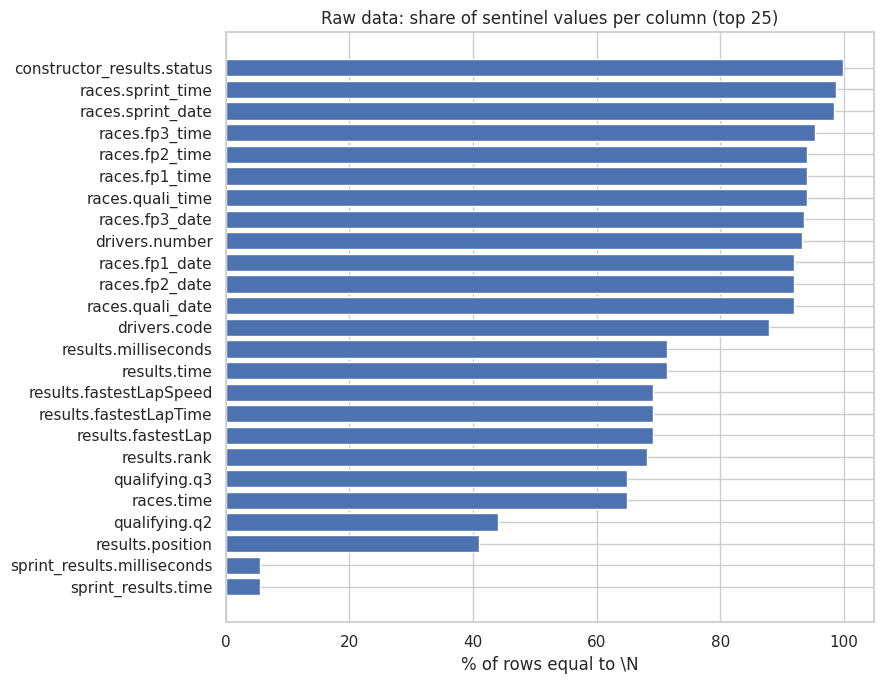

In [7]:
top = sentinel_df.head(25)
plt.figure(figsize=(9, 7))
plt.barh(top["table"] + "." + top["column"], top["pct"])
plt.gca().invert_yaxis()
plt.xlabel("% of rows equal to \\N")
plt.title("Raw data: share of sentinel values per column (top 25)")
plt.tight_layout(); plt.show()

In [8]:
auto = pd.read_csv(os.path.join(DATA_DIR, "results.csv"))
has_sentinel = (raw["results"] == SENTINEL).any()

typing_check = pd.DataFrame({
    "auto_dtype": auto.dtypes.astype(str),
    "contains_\\N": has_sentinel,
})
typing_check.sort_values("contains_\\N", ascending=False)

,auto_dtype,contains_\N
fastestLapSpeed,object,True
fastestLapTime,object,True
number,object,True
rank,object,True
position,object,True
fastestLap,object,True
milliseconds,object,True
time,object,True
resultId,int64,False
laps,int64,False


**TODO (EDA owner):** add more before-cleaning plots, e.g.
- races per season and entrants per race (field size over time)
- podium share per season (class imbalance)
- qualifying coverage per season (needs `qualifying` joined to `races`)

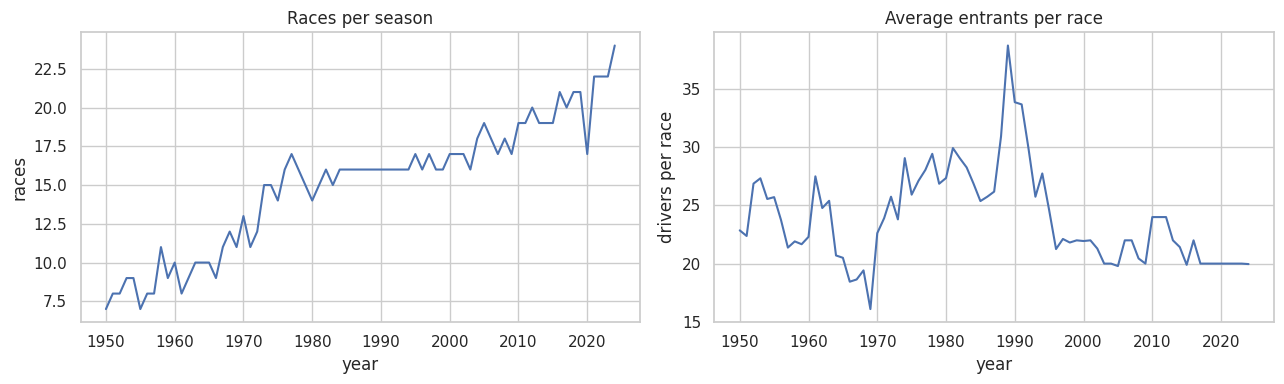

In [9]:
# How many races per season, and how many drivers enter each race?
res_y = (raw["results"][["raceId", "driverId", "positionOrder"]].astype(int)
         .merge(raw["races"][["raceId", "year"]].astype(int), on="raceId"))

per_season = res_y.groupby("year").agg(races=("raceId", "nunique"), entries=("driverId", "size"))
per_season["entrants_per_race"] = per_season["entries"] / per_season["races"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_season["races"].plot(ax=ax[0], title="Races per season")
per_season["entrants_per_race"].plot(ax=ax[1], title="Average entrants per race")
ax[0].set_ylabel("races"); ax[1].set_ylabel("drivers per race")
plt.tight_layout(); plt.show()

**Observation:** races per season grew from ~7 (1950) to ~24 (2024), so modern seasons contribute most rows.
Average entrants per race peaked at ~39 around 1989 (many non-qualifiers recorded in `results`) and has been ~20 since the late 1990s.
→ Field size varies a lot by era, which changes the podium base rate (next plot). Rows for drivers who never started (DNQ/DNPQ) need a keep/drop decision.

Overall podium rate: 12.7%


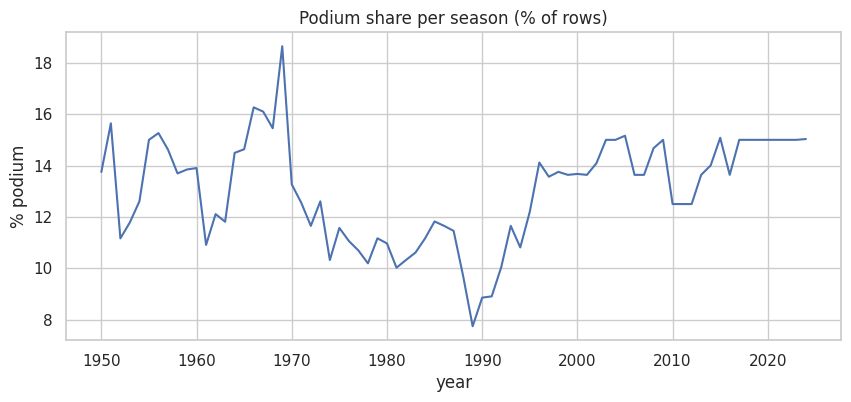

In [10]:
# What fraction of driver-race rows are podiums each season?
res_y["podium"] = (res_y["positionOrder"] <= 3).astype(int)
podium_rate = res_y.groupby("year")["podium"].mean() * 100

print(f"Overall podium rate: {res_y['podium'].mean():.1%}")
podium_rate.plot(figsize=(10, 4), title="Podium share per season (% of rows)")
plt.ylabel("% podium"); plt.show()

**Observation:** the overall podium rate is 12.7%, so the target is imbalanced (≈1 positive per 7 rows).
It drops to ~8% around 1989, when fields were largest, and is stable at ~15% (3 out of 20) in the modern era.


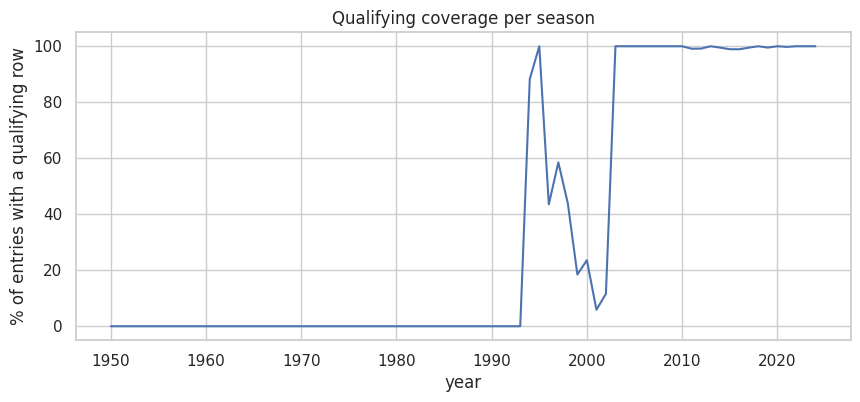

In [11]:
# For each season, what % of race entries have a qualifying record?
q_keys = raw["qualifying"][["raceId", "driverId"]].astype(int).drop_duplicates()
cov = res_y.merge(q_keys, on=["raceId", "driverId"], how="left", indicator=True)
cov["has_quali"] = cov["_merge"] == "both"
coverage = cov.groupby("year")["has_quali"].mean() * 100

coverage.plot(figsize=(10, 4), title="Qualifying coverage per season")
plt.ylabel("% of entries with a qualifying row"); plt.show()

**Observation:** qualifying records are absent before 1994, partial between 1996 and 2002 (5–60% of entries),
and complete from 2003 onwards. This is a gap in the dataset, not a rule change.
`grid` (from `results`) is available for all seasons.
→ Qualifying-based features are only reliable from 2003. Decision: _[team to choose: train from 2003 / keep all years with a has_quali flag / grid fallback]_ because _[reason]_.

In [12]:
# Validity check: are values in a possible range?
r = raw["results"].apply(pd.to_numeric, errors="coerce")
d = raw["drivers"].copy()
races_dt = raw["races"][["raceId", "date"]].assign(
    raceId=lambda x: x["raceId"].astype(int), date=lambda x: pd.to_datetime(x["date"]))

checks = {
    "grid < 0":                   (r["grid"] < 0).sum(),
    "grid == 0 (pit-lane / no start)": (r["grid"] == 0).sum(),
    "positionOrder < 1":          (r["positionOrder"] < 1).sum(),
    "points < 0":                 (r["points"] < 0).sum(),
    "laps < 0":                   (r["laps"] < 0).sum(),
}

# Driver age at each race: anyone younger than 16 or older than 60?
age = (r[["raceId", "driverId"]].astype(int)
       .merge(races_dt, on="raceId")
       .merge(d[["driverId", "dob"]].assign(driverId=lambda x: x["driverId"].astype(int),
                                            dob=lambda x: pd.to_datetime(x["dob"], errors="coerce")), on="driverId"))
age["age"] = (age["date"] - age["dob"]).dt.days / 365.25
checks["driver age < 16"] = (age["age"] < 16).sum()
checks["driver age > 60"] = (age["age"] > 60).sum()

pd.Series(checks, name="rows").to_frame()

,rows
grid < 0,0
grid == 0 (pit-lane / no start),1638
positionOrder < 1,0
points < 0,0
laps < 0,0
driver age < 16,0
driver age > 60,0


FINAL NOTES***
## Summary of data problems found in EDA

Each problem below was identified from the outputs above. The last column shows where (or how) it is handled.

### A. Format problems (fixed in Section 3)

| # | Problem | Explanation | Evidence | Planned fix |
|---|---|---|---|---|
| 1 | `\N` used as a missing-value placeholder | The dataset writes "missing" as the text `\N`, which pandas does not recognise as empty | Sentinel audit: 30 columns affected | Replace `\N` with `NaN` |
| 2 | Numbers and dates stored as text | One `\N` in a column forces the whole column to be read as text, so no math or comparisons are possible (e.g. `"10" < "3"` as text) | Typing check: every column containing `\N` loads as `object` | Convert each column to its real type (int, float, datetime) |
| 3 | Lap and pit-stop times stored as text (`"1:27.264"`) | Times cannot be subtracted or averaged, so features like *gap to pole* cannot be computed | `qualifying.q1/q2/q3`, `pit_stops.duration`, `results.fastestLapTime` | Convert to numeric seconds (`87.264`) |
| 4 | Columns with almost no data | Some columns are nearly empty and add nothing | `constructor_results.status` 99.9% missing | Document and drop |

### B. Structural problems (checked in Sections 4–5)

| # | Problem | Explanation | Planned check |
|---|---|---|---|
| 5 | Possible duplicate (raceId, driverId) rows | In the 1950s two drivers could share one car, so a driver may appear twice in a race. The modeling table needs exactly one row per driver per race | Count duplicates, then apply a documented deduplication rule |
| 6 | Possible broken links between tables | An ID in one table (e.g. `results.driverId`) might not exist in the table it points to | Primary-key and foreign-key audit |

### C. Missing values with a real-world meaning (handled in cleaning / feature engineering)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 7 | `q2` / `q3` empty for many drivers | Qualifying is a knockout: only 15 drivers reach Q2 and 10 reach Q3, so emptiness means "eliminated earlier", not an error | q2 44%, q3 65% missing | Do not fill with 0 (that would mean a 0-second lap). Use `quali_position` and a `reached_Q3` flag instead of raw times |
| 8 | `position` empty for unclassified drivers | Drivers who complete less than 90% of the race distance get no official position | `results.position` 41% missing | Target uses `positionOrder` (always filled) instead of `position` |
| 9 | Qualifying data missing for whole eras | The dataset has no qualifying records before 1994 and only partial records in 1996–2002 (a recording gap, not a rule change) | Qualifying-coverage plot | **Team decision:** train from 2003 / keep all years with a `has_quali` flag / fall back to `grid` |

### D. Misleading or era-dependent values (team decisions)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 10 | `grid = 0` | Means a pit-lane start (car changed after qualifying) or a driver who never started. As a number, 0 looks *better* than pole position (1), the opposite of reality | Validity check | Recode (e.g. to the back of the grid) and/or add a `pit_lane_start` flag |
| 11 | Drivers who never started (DNQ / DNPQ) | In the 1980s–90s up to 39 cars entered but only 26 could start. Non-starters cannot reach the podium | Entrants peak of ~39 around 1989 | **Team decision:** drop non-starters from the modeling table or keep them as guaranteed negatives |
| 12 | Indy 500 races (1950–1960) | Counted for the championship but almost no regular F1 drivers entered, so it behaves like a different series | F1 brief | Exclude and document |
| 13 | Field size varies by era (~20 to ~39) | The same grid position means different things: 15th of 20 is near the back, 15th of 39 is mid-field | Entrants-per-race plot | Consider a relative-grid feature (`grid / field_size`) |
| 14 | Imbalanced target that changes by era | Only 12.7% of rows are podiums, so a model that always says "no" is 87% accurate but useless. The rate ranges from ~8% (large fields) to ~15% (modern era) | Podium-share plot | Use PR-AUC as the primary metric; consider class weighting and the training-year decision |

### E. Risks for later sections

| # | Problem | Explanation | Where handled |
|---|---|---|---|
| 15 | Team renames reset history | The same team under a new name (Toleman → Benetton → Renault → Lotus → Alpine) gets a new `constructorId` | Note for constructor-form features |
| 16 | Leakage columns next to valid ones | `results` mixes pre-race info (`grid`) with post-race info (`points`, `laps`, `statusId`, `time`) | Feature section: only pre-race columns allowed |

## 3. Cleaning: sentinels & semantic typing
Steps, applied to copies:
1. Replace `\N` with `NaN`.
2. Convert ID / numeric columns to numbers.
3. Convert date strings to `datetime`.
4. Convert lap-time / duration strings (`"1:27.264"`, `"21.664"`) to numeric **seconds**.

In [13]:
def to_seconds(s):
    """'1:27.264' -> 87.264 ; '21.664' -> 21.664 ; '1:02:03.5' -> 3723.5 ; NaN/garbage -> NaN"""
    if pd.isna(s):
        return np.nan
    s = str(s).strip().lstrip("+")
    try:
        parts = [float(p) for p in s.split(":")]
    except ValueError:
        return np.nan
    secs = 0.0
    for p in parts:
        secs = secs * 60 + p
    return secs

assert to_seconds("1:27.264") == 87.264
assert to_seconds("21.664") == 21.664
assert np.isnan(to_seconds(np.nan))

In [14]:
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
             "drivers": ["dob"]}
TIME_COLS = {"qualifying": ["q1", "q2", "q3"],
             "lap_times": ["time"],
             "pit_stops": ["duration"],
             "results": ["fastestLapTime"],
             "sprint_results": ["fastestLapTime"]}
# Text columns that must stay strings
TEXT_COLS = {"circuitRef", "name", "location", "country", "url", "constructorRef", "nationality",
             "driverRef", "code", "forename", "surname", "positionText", "status", "time"}

clean = {}
for t, df in raw.items():
    d = df.copy().replace([SENTINEL, ""], np.nan)   # treat both "\N" and blank cells as missing
    for col in d.columns:
        if col in DATE_COLS.get(t, []):
            d[col] = pd.to_datetime(d[col], errors="coerce")
        elif col in TIME_COLS.get(t, []):
            d[col + "_s"] = d[col].map(to_seconds)      # keep original text, add numeric seconds
        elif col not in TEXT_COLS and not col.endswith("_time"):
            converted = pd.to_numeric(d[col], errors="coerce")
            # only convert if it doesn't destroy real values
            if converted.notna().sum() == d[col].notna().sum():
                d[col] = converted
    clean[t] = d

# Sanity: raw must be untouched
assert (raw["results"] == SENTINEL).any().any(), "raw was modified!"
clean["results"].dtypes

resultId              int64
raceId                int64
driverId              int64
constructorId         int64
number              float64
grid                  int64
position            float64
positionText         object
positionOrder         int64
points              float64
laps                  int64
time                 object
milliseconds        float64
fastestLap          float64
rank                float64
fastestLapTime       object
fastestLapSpeed     float64
statusId              int64
fastestLapTime_s    float64
dtype: object

In [15]:
# Check conversions did not silently lose values (non-null before vs after)
loss = []
for t in TIME_COLS:
    for col in TIME_COLS[t]:
        if col in clean[t]:
            before, after = clean[t][col].notna().sum(), clean[t][col + "_s"].notna().sum()
            loss.append({"table": t, "column": col, "non_null_text": before, "non_null_seconds": after, "lost": before - after})
pd.DataFrame(loss)

,table,column,non_null_text,non_null_seconds,lost
0,qualifying,q1,10338,10338,0
1,qualifying,q2,5847,5847,0
2,qualifying,q3,3629,3629,0
3,lap_times,time,589081,589081,0
4,pit_stops,duration,11371,11371,0
5,results,fastestLapTime,8252,8252,0
6,sprint_results,fastestLapTime,351,351,0


In [16]:
# constructor_results.status is 99.9% empty (see sentinel audit) → drop it
clean["constructor_results"] = clean["constructor_results"].drop(columns="status", errors="ignore")

In [17]:
# 1) No "\N" left anywhere
remaining = {t: int((df.astype(str) == SENTINEL).sum().sum()) for t, df in clean.items()}
print("Remaining \\N per table:", remaining)

# 2) Types before vs after for the main table
pd.DataFrame({"raw_dtype": raw["results"].dtypes.astype(str),
              "clean_dtype": clean["results"].dtypes.astype(str)})

Remaining \N per table: {'circuits': 0, 'constructors': 0, 'constructor_results': 0, 'constructor_standings': 0, 'drivers': 0, 'driver_standings': 0, 'races': 0, 'results': 0, 'qualifying': 0, 'lap_times': 0, 'pit_stops': 0, 'sprint_results': 0, 'seasons': 0, 'status': 0}


,raw_dtype,clean_dtype
constructorId,object,int64
driverId,object,int64
fastestLap,object,float64
fastestLapSpeed,object,float64
fastestLapTime,object,object
fastestLapTime_s,NaN,float64
grid,object,int64
laps,object,int64
milliseconds,object,float64
number,object,float64


**Cleaning summary (problems 1–4):**
- Replaced the `\N` placeholder with `NaN` in all tables (verified: 0 remaining).
- Converted ID, count and numeric columns to numbers, and date columns to `datetime`.
  A column is only converted when no value is lost; genuine text columns (names, `positionText`, race-gap `time`) stay as text.
- Converted lap and pit-stop times to seconds in new `_s` columns, keeping the original text for traceability (loss check: 0 values lost).
- Dropped `constructor_results.status` (99.9% missing).
- Raw tables are untouched (assert check passed).

Problems 9–12 (training years, `grid = 0`, non-starters, Indy 500) are left for a team decision.

## 4. Key audit: primary & foreign keys

In [18]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk_report = []
for t, keys in PRIMARY_KEYS.items():
    d = clean[t]
    pk_report.append({"table": t, "key": "+".join(keys),
                      "null_rows": int(d[keys].isna().any(axis=1).sum()),
                      "duplicate_rows": int(d.duplicated(keys).sum())})
pd.DataFrame(pk_report)

,table,key,null_rows,duplicate_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,qualifying,qualifyId,0,0
8,sprint_results,resultId,0,0
9,driver_standings,driverStandingsId,0,0


In [19]:
# (child table, child column, parent table, parent column)
FOREIGN_KEYS = [("races", "year", "seasons", "year"), ("races", "circuitId", "circuits", "circuitId")]
for child in ["results", "qualifying", "sprint_results", "driver_standings", "lap_times", "pit_stops"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"), (child, "driverId", "drivers", "driverId")]
for child in ["results", "qualifying", "sprint_results", "constructor_standings", "constructor_results"]:
    FOREIGN_KEYS += [(child, "constructorId", "constructors", "constructorId")]
FOREIGN_KEYS += [("constructor_standings", "raceId", "races", "raceId"),
                 ("constructor_results", "raceId", "races", "raceId"),
                 ("results", "statusId", "status", "statusId"),
                 ("sprint_results", "statusId", "status", "statusId")]

fk_report = []
for ct, cc, pt, pc in FOREIGN_KEYS:
    vals = clean[ct][cc].dropna()
    orphans = ~vals.isin(clean[pt][pc])
    fk_report.append({"child": f"{ct}.{cc}", "parent": f"{pt}.{pc}",
                      "null_fk": int(clean[ct][cc].isna().sum()), "orphans": int(orphans.sum())})
fk_df = pd.DataFrame(fk_report)
fk_df

,child,parent,null_fk,orphans
0,races.year,seasons.year,0,0
1,races.circuitId,circuits.circuitId,0,0
2,results.raceId,races.raceId,0,0
3,results.driverId,drivers.driverId,0,0
4,qualifying.raceId,races.raceId,0,0
5,qualifying.driverId,drivers.driverId,0,0
6,sprint_results.raceId,races.raceId,0,0
7,sprint_results.driverId,drivers.driverId,0,0
8,driver_standings.raceId,races.raceId,0,0
9,driver_standings.driverId,drivers.driverId,0,0


**Key audit result:** every table's primary key is unique and non-null, and every foreign key
(results/qualifying/sprint/standings/lap times/pit stops → races, drivers, constructors, status; races → circuits, seasons)
points to an existing row (0 duplicates, 0 nulls, 0 orphans).
→ Joins between tables will not drop or mismatch rows, so no key-related cleaning is needed.

**TODO:** interpret the tables above. If any orphans or duplicates appear, show examples and decide how to handle them.

## 5. Grain: one row per (raceId, driverId)
The modeling table needs exactly one row per driver per race. Shared drives (mainly the 1950s) break this.

176 rows involved in 85 duplicated (raceId, driverId) pairs


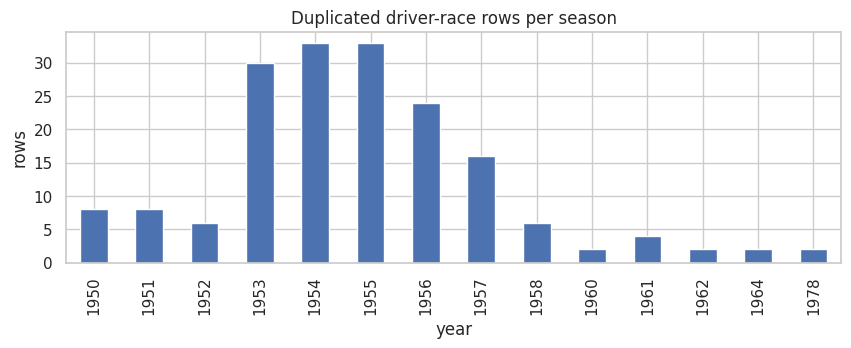

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s,year,name
0,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,NaN,1978,Italian Grand Prix
1,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,NaN,1978,Italian Grand Prix
2,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60,NaN,1964,United States Grand Prix
175,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98,NaN,1964,United States Grand Prix
3,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,NaN,1962,British Grand Prix
4,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,NaN,1962,British Grand Prix
5,17962,742,475,102,26.0,20,NaN,D,19,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,1961,British Grand Prix
6,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23,NaN,1961,British Grand Prix
7,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6,NaN,1961,United States Grand Prix
174,24303,745,418,172,21.0,15,11.0,11,11,0.0,92,NaN,NaN,NaN,NaN,NaN,NaN,18,NaN,1961,United States Grand Prix


In [20]:
res = clean["results"]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
print(f"{dup_mask.sum()} rows involved in {res[dup_mask].groupby(['raceId','driverId']).ngroups} duplicated (raceId, driverId) pairs")
dups.groupby("year").size().plot(kind="bar", figsize=(10, 3), title="Duplicated driver-race rows per season")
plt.ylabel("rows"); plt.show()
dups.sort_values(["raceId", "driverId"]).head(10)

In [21]:
# PROPOSED RULE (team to confirm + justify in markdown):
# keep the car the driver STARTED in (grid > 0); if still tied, keep the best positionOrder.
def dedupe_results(df):
    d = df.copy()
    d["_started"] = (d["grid"].fillna(0) > 0).astype(int)
    d = d.sort_values(["raceId", "driverId", "_started", "positionOrder"], ascending=[True, True, False, True])
    return d.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_started")

results_dedup = dedupe_results(res)
assert not results_dedup.duplicated(["raceId", "driverId"]).any()
print(f"rows before: {len(res)}, after: {len(results_dedup)}, removed: {len(res) - len(results_dedup)}")

rows before: 26759, after: 26668, removed: 91


**Grain fix (problem 5):** 85 (raceId, driverId) pairs appear more than once (176 rows), almost all in 1950–1957,
when drivers could take over a teammate's car mid-race (banned after 1957).
A driver with two rows in the same race would get two contradicting labels (e.g. one podium, one not) and be double-counted in statistics.

**Rule:** keep the row of the car the driver **started** in (`grid > 0`); if still tied, keep the best `positionOrder`.
**Justification:** the prediction is made before the race, when only the starting car is known; a mid-race car swap is post-race information.
**Result:** 91 rows removed (26,759 → 26,668); verified one row per (raceId, driverId).

In [22]:
dups[dups["year"] == 1978]

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s,year,name
0,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,NaN,1978,Italian Grand Prix
1,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,NaN,1978,Italian Grand Prix


In [23]:
# From here on, the deduplicated table IS the clean results table
clean["results"] = results_dedup

In [24]:
GRAIN = {
    "qualifying":            ["raceId", "driverId"],
    "sprint_results":        ["raceId", "driverId"],
    "driver_standings":      ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results":   ["raceId", "constructorId"],
    "races":                 ["year", "round"],  
}
pd.DataFrame([{"table": t, "grain": " + ".join(k), "duplicate_rows": int(clean[t].duplicated(k).sum())}
              for t, k in GRAIN.items()])

,table,grain,duplicate_rows
0,qualifying,raceId + driverId,0
1,sprint_results,raceId + driverId,0
2,driver_standings,raceId + driverId,0
3,constructor_standings,raceId + constructorId,0
4,constructor_results,raceId + constructorId,0
5,races,year + round,0


## 6. EDA after cleaning
**TODO:** repeat the key before-cleaning plots and show what changed.

In [25]:
summary = pd.DataFrame({
    "rows_raw":      {t: len(raw[t]) for t in TABLES},
    "rows_clean":    {t: len(clean[t]) for t in TABLES},
    "missing_raw":   {t: int(((raw[t] == SENTINEL) | (raw[t] == "")).sum().sum()) for t in TABLES},
    # count only columns that exist in raw (ignore the added *_s seconds columns)
    "missing_clean": {t: int(clean[t][clean[t].columns.intersection(raw[t].columns)].isna().sum().sum()) for t in TABLES},
})
summary["rows_removed"] = summary["rows_raw"] - summary["rows_clean"]
summary

,rows_raw,rows_clean,missing_raw,missing_clean,rows_removed
circuits,77,77,0,0,0
constructors,212,212,0,0,0
constructor_results,12625,12625,12608,0,0
constructor_standings,13391,13391,0,0,0
drivers,861,861,1559,1559,0
driver_standings,34863,34863,0,0,0
races,1125,1125,11349,11349,0
results,26759,26668,122887,122260,91
qualifying,10494,10494,11668,11668,0
lap_times,589081,589081,0,0,0


**Before vs after cleaning:**
- Row counts are unchanged in every table except `results`, where 91 duplicate (raceId, driverId) rows were removed.
- Missing values are preserved: every `\N` or blank cell in the raw data is now a real `NaN` in the clean data,
  so nothing was lost or invented (the comparison counts only original columns; the added `*_s` seconds columns repeat their source's gaps).
- `constructor_results` drops to 0 missing because its 99.9%-empty `status` column was removed.
- `results` has slightly fewer missing values than raw because the removed duplicate rows took their gaps with them.

In [26]:
# ===== Data decisions (fixed for every modeling attempt) =====
EXCLUDE_INDY500   = True   # decision 4
DROP_NON_STARTERS = True   # decision 3
# decision 2 (grid = 0 → back of grid + flag) is always applied

base = clean["results"].merge(
    clean["races"][["raceId", "year", "round", "name", "date", "circuitId"]], on="raceId")

is_indy     = base["name"].str.contains("Indianapolis 500", case=False)
non_starter = (base["grid"] == 0) & (base["laps"] == 0)
pit_lane    = (base["grid"] == 0) & (base["laps"] > 0)

print(f"Rows before decisions:   {len(base)}")
print(f"  Indy 500 rows:         {is_indy.sum()}")
print(f"  Non-starter rows:      {(non_starter & ~is_indy).sum()}")
print(f"  Pit-lane-start rows:   {(pit_lane & ~is_indy).sum()}")

# Decisions 3 + 4: keep only real starters of real F1 races
keep = pd.Series(True, index=base.index)
if EXCLUDE_INDY500:   keep &= ~is_indy
if DROP_NON_STARTERS: keep &= ~non_starter
base = base[keep].copy()

# Decision 2: pit-lane starters → back of the grid, plus a flag
base["pit_lane_start"] = ((base["grid"] == 0) & (base["laps"] > 0)).astype(int)
back_of_grid = base.groupby("raceId")["grid"].transform("max") + 1
base["grid"] = np.where(base["pit_lane_start"] == 1, back_of_grid, base["grid"])

# Target: podium = finished in the top 3
base["podium"] = (base["positionOrder"] <= 3).astype(int)

assert (base["grid"] > 0).all(), "grid = 0 still present"
assert not base.duplicated(["raceId", "driverId"]).any(), "duplicate driver-race rows"
print(f"Rows after decisions:    {len(base)}")

Rows before decisions:   26668
  Indy 500 rows:         381
  Non-starter rows:      1563
  Pit-lane-start rows:   72
Rows after decisions:    24724


**Data decisions (applied to every modeling attempt):** 26,668 → 24,724 rows.
- **Indy 500 excluded** (381 rows): counted for the championship 1950–1960, but entered almost exclusively by American drivers who did not race other F1 events, so it behaves like a separate series.
- **Non-starters dropped** (1,563 rows, `grid = 0` and `laps = 0`): did-not-qualify / did-not-start entries cannot reach the podium, and at the prediction cutoff (grid set) it is already known they are not racing.
- **Pit-lane starters kept** (72 rows): recoded to the back of the grid (largest grid in the race + 1) and flagged with `pit_lane_start = 1`. `laps` is used only to identify these rows; a pit-lane start is announced before the race.
- **Target:** `podium = 1` if `positionOrder ≤ 3`.
- Verified: no `grid = 0` and no duplicate (raceId, driverId) rows remain.

**Training years (decision 1)** is the only setting that differs between attempts:
`from_2003` (complete qualifying data) vs `all_years`. Both are evaluated on the same 2020–2021 validation set in Section 10.

In [27]:
# ===== Decision 1: training years (the ONE thing that differs between attempts) =====
YEAR_OPTIONS = {"from_2003": 2003, "all_years": 1950}

model_bases = {name: base[base["year"] >= start].copy() for name, start in YEAR_OPTIONS.items()}

pd.DataFrame({
    name: {"first_year": d["year"].min(),
           "rows_total": len(d),
           "rows_train (≤2019)": int((d["year"] <= TRAIN_END).sum()),
           "podium_rate": f"{d['podium'].mean():.1%}"}
    for name, d in model_bases.items()
}).T

,first_year,rows_total,rows_train (≤2019),podium_rate
from_2003,2003,8956,6821,14.3%
all_years,1950,24724,22589,13.6%


**Training-year options:** `from_2003` has 6,821 training rows (2003–2019) and `all_years` has 22,589 (1950–2019),
about 3.3× more, but from eras with different field sizes, reliability and no qualifying data.
Both share the same 2,135 validation/test rows (2020+), so they are compared on identical races.
Podium rates are similar (14.3% vs 13.6%) after removing non-starters, which had inflated the "no podium" rows in older seasons.

## 7. Data-engineering questions
Each answer needs: result table, plot, and a note on grain, missingness and the pre-race cutoff.

### Q1. Which circuits convert a front-row start into a podium most often, before vs after 2014?
Tables: `results` + `qualifying` + `races` + `circuits`. Compare qualifying P1–2 vs grid P1–2.

### Q2. Home-race podium effect, controlling for grid position
Tables: `results` + `drivers` + `races` + `circuits`. Needs a nationality → country mapping.

### Q3. Mechanical-retirement rate per constructor, 2014–2021 vs 2022–2024
Tables: `results` + `status` + `constructors` + `races`. Needs a documented status → mechanical mapping.

In [28]:
# Q1 base: one row per driver-race (from `base`: Indy 500 and non-starters already removed)
q_pos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
circ  = clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"})

fr = (base.merge(q_pos, on=["raceId", "driverId"], how="left")
          .merge(circ, on="circuitId"))
fr["period"]      = np.where(fr["year"] >= 2014, "2014+", "pre-2014")
fr["front_grid"]  = fr["grid"] <= 2
fr["front_quali"] = fr["quali_pos"] <= 2            # empty qualifying → False
has_quali = fr["quali_pos"].notna()

# Overall conversion rate per period, for both definitions
overall = pd.DataFrame({
    "grid front row":       fr[fr["front_grid"]].groupby("period")["podium"].mean(),
    "qualifying front row": fr[has_quali & fr["front_quali"]].groupby("period")["podium"].mean(),
}).loc[["pre-2014", "2014+"]]
print("Front-row → podium conversion rate:")
display((overall * 100).round(1))

# How often do the two definitions disagree? (penalties / grid changes)
diff = fr[has_quali & (fr["front_grid"] != fr["front_quali"])]
print(f"\nRows where qualifying front row ≠ grid front row: {len(diff)} "
      f"(out of {(has_quali & (fr['front_grid'] | fr['front_quali'])).sum()} front-row rows with qualifying data)")

Front-row → podium conversion rate:


,grid front row,qualifying front row
period,,
pre-2014,56.3,64.7
2014+,76.0,74.0



Rows where qualifying front row ≠ grid front row: 72 (out of 1022 front-row rows with qualifying data)


In [32]:
MIN_STARTS = 10   # at least 10 front-row starts per period (≈5 races), so one lucky race can't give 100%

def circuit_conversion(df, flag):
    s = (df[df[flag]].groupby(["circuit", "period"])["podium"]
           .agg(starts="size", rate="mean").unstack("period"))
    s = s[(s["starts"] >= MIN_STARTS).all(axis=1)]          # enough starts in BOTH periods
    out = pd.DataFrame({
        "starts_pre":   s["starts"]["pre-2014"], "rate_pre":   s["rate"]["pre-2014"],
        "starts_2014+": s["starts"]["2014+"],    "rate_2014+": s["rate"]["2014+"],
    })
    out["change"]      = out["rate_2014+"] - out["rate_pre"]
    out["rank_pre"]    = out["rate_pre"].rank(ascending=False, method="min").astype(int)
    out["rank_2014+"]  = out["rate_2014+"].rank(ascending=False, method="min").astype(int)
    out["rank_change"] = out["rank_pre"] - out["rank_2014+"]   # positive = moved up after 2014
    return out.sort_values("rate_2014+", ascending=False)

q1_grid  = circuit_conversion(fr, "front_grid")
q1_quali = circuit_conversion(fr[has_quali], "front_quali")
print(f"Grid definition: {len(q1_grid)} circuits with ≥{MIN_STARTS} front-row starts in both periods")
display(q1_grid.style.format({"rate_pre": "{:.0%}", "rate_2014+": "{:.0%}", "change": "{:+.0%}"}))

print(f"\nQualifying definition: {len(q1_quali)} circuits")
display(q1_quali.style.format({"rate_pre": "{:.0%}", "rate_2014+": "{:.0%}", "change": "{:+.0%}"}))

Grid definition: 16 circuits with ≥10 front-row starts in both periods


,starts_pre,rate_pre,starts_2014+,rate_2014+,change,rank_pre,rank_2014+,rank_change
circuit,,,,,,,,
Suzuka Circuit,50.000000,70%,18.000000,89%,+19%,1,1,0
Yas Marina Circuit,10.000000,60%,22.000000,86%,+26%,6,2,4
Circuit de Monaco,120.000000,49%,20.000000,85%,+36%,15,3,12
Circuit de Barcelona-Catalunya,46.000000,65%,22.000000,82%,+17%,4,4,0
Circuit de Spa-Francorchamps,89.000000,55%,22.000000,82%,+27%,12,4,8
Autódromo José Carlos Pace,62.000000,60%,19.000000,79%,+19%,8,6,2
Shanghai International Circuit,20.000000,65%,14.000000,79%,+14%,5,7,-2
Circuit Gilles Villeneuve,68.000000,53%,18.000000,78%,+25%,13,8,5
Silverstone Circuit,94.000000,56%,24.000000,75%,+19%,10,9,1



Qualifying definition: 14 circuits


,starts_pre,rate_pre,starts_2014+,rate_2014+,change,rank_pre,rank_2014+,rank_change
circuit,,,,,,,,
Suzuka Circuit,26.000000,77%,18.000000,89%,+12%,1,1,0
Circuit de Monaco,28.000000,64%,20.000000,85%,+21%,7,2,5
Circuit de Spa-Francorchamps,24.000000,54%,22.000000,82%,+28%,13,3,10
Yas Marina Circuit,10.000000,60%,22.000000,82%,+22%,9,3,6
Circuit de Barcelona-Catalunya,30.000000,63%,22.000000,82%,+18%,8,3,5
Shanghai International Circuit,20.000000,70%,14.000000,79%,+9%,2,6,-4
Silverstone Circuit,32.000000,66%,24.000000,75%,+9%,4,7,-3
Autodromo Nazionale di Monza,26.000000,65%,22.000000,73%,+7%,5,8,-3
Circuit Gilles Villeneuve,26.000000,58%,18.000000,72%,+15%,12,9,3


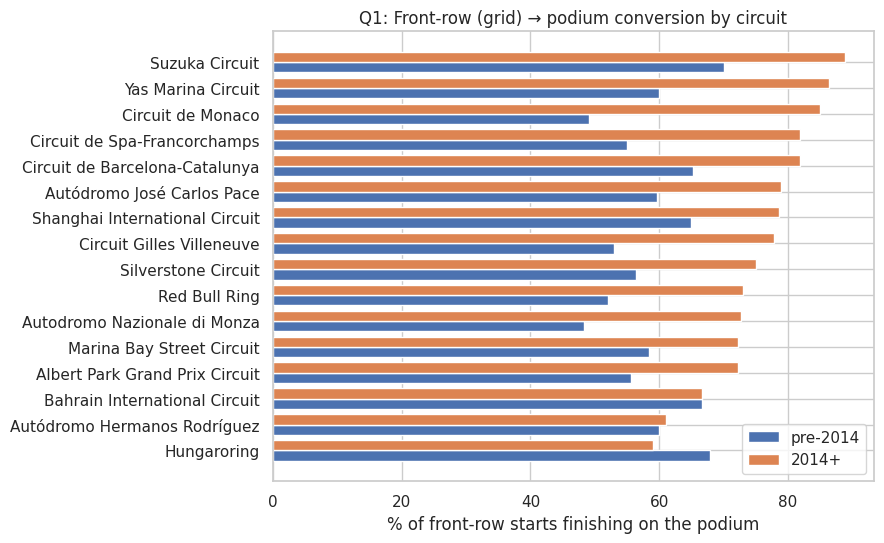

In [33]:
plot_df = q1_grid.sort_values("rate_2014+")
y = np.arange(len(plot_df))

plt.figure(figsize=(9, max(4, 0.35 * len(plot_df))))
plt.barh(y - 0.2, plot_df["rate_pre"] * 100,   height=0.4, label="pre-2014")
plt.barh(y + 0.2, plot_df["rate_2014+"] * 100, height=0.4, label="2014+")
plt.yticks(y, plot_df.index)
plt.xlabel("% of front-row starts finishing on the podium")
plt.title("Q1: Front-row (grid) → podium conversion by circuit")
plt.legend(); plt.tight_layout(); plt.show()

In [34]:
# Driver nationality (demonym) → country name as used in circuits.country
NAT_TO_COUNTRY = {
    "British": "UK", "English": "UK", "Scottish": "UK", "Welsh": "UK", "Northern Irish": "UK",
    "German": "Germany", "East German": "Germany", "West German": "Germany",
    "Italian": "Italy", "French": "France", "Spanish": "Spain", "Portuguese": "Portugal",
    "Belgian": "Belgium", "Dutch": "Netherlands", "Swiss": "Switzerland", "Austrian": "Austria",
    "Swedish": "Sweden", "Hungarian": "Hungary", "Monegasque": "Monaco", "Russian": "Russia",
    "Turkish": "Turkey", "American": "USA", "Canadian": "Canada", "Mexican": "Mexico",
    "Brazilian": "Brazil", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Australian": "Australia", "Japanese": "Japan", "Chinese": "China", "Malaysian": "Malaysia",
    "Singaporean": "Singapore", "Indian": "India", "Korean": "Korea", "South African": "South Africa",
    "Moroccan": "Morocco", "Bahraini": "Bahrain", "Saudi": "Saudi Arabia", "Qatari": "Qatar",
    "Azerbaijani": "Azerbaijan", "Emirati": "UAE",
}
# Different spellings of the same country on the circuit side
COUNTRY_ALIASES = {"United States": "USA", "United Kingdom": "UK", "Great Britain": "UK",
                   "United Arab Emirates": "UAE", "South Korea": "Korea"}

drv = clean["drivers"][["driverId", "nationality"]].copy()
drv["home_country"] = drv["nationality"].map(NAT_TO_COUNTRY)
circ_c = clean["circuits"][["circuitId", "country"]].copy()
circ_c["circuit_country"] = circ_c["country"].replace(COUNTRY_ALIASES)

h = (base.merge(drv, on="driverId")
         .merge(circ_c[["circuitId", "circuit_country"]], on="circuitId"))
h["home"] = (h["home_country"] == h["circuit_country"]).astype(int)

# --- Mapping audit: prove the mapping didn't silently miss anything ---
circuit_countries = set(circ_c["circuit_country"].dropna())
print("Nationalities NOT in the mapping (these drivers can never be 'home'):")
print(drv.loc[drv["home_country"].isna(), "nationality"].value_counts().to_string(), "\n")
print("Mapped countries with no circuit (fine if the country never hosted a race):",
      sorted(set(NAT_TO_COUNTRY.values()) - circuit_countries))
print("Circuit countries with no mapped driver nationality:",
      sorted(circuit_countries - set(drv["home_country"].dropna())))
print(f"\nHome rows: {h['home'].sum()} of {len(h)} ({h['home'].mean():.1%})")

Nationalities NOT in the mapping (these drivers can never be 'home'):
nationality
New Zealander        10
Finnish               9
Danish                5
Irish                 5
Rhodesian             4
Uruguayan             4
Colombian             3
Venezuelan            3
Thai                  2
Chilean               1
Czech                 1
Polish                1
Liechtensteiner       1
American-Italian      1
Argentine-Italian     1
Indonesian            1
Argentinian           1 

Mapped countries with no circuit (fine if the country never hosted a race): []
Circuit countries with no mapped driver nationality: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']

Home rows: 1943 of 24724 (7.9%)


In [35]:
bins   = [0, 1, 3, 6, 10, 15, np.inf]
labels = ["1", "2-3", "4-6", "7-10", "11-15", "16+"]
h["grid_bucket"] = pd.cut(h["grid"], bins=bins, labels=labels)

tab = h.groupby(["grid_bucket", "home"], observed=True)["podium"].agg(["size", "mean"]).unstack("home")
q2 = pd.DataFrame({
    "away_starts": tab["size"][0], "home_starts": tab["size"][1],
    "away_rate":   tab["mean"][0], "home_rate":   tab["mean"][1],
})
q2["difference"] = q2["home_rate"] - q2["away_rate"]
display(q2.style.format({"away_rate": "{:.1%}", "home_rate": "{:.1%}", "difference": "{:+.1%}"}))

raw_diff = h.loc[h["home"] == 1, "podium"].mean() - h.loc[h["home"] == 0, "podium"].mean()
adj_diff = np.average(q2["difference"], weights=q2["home_starts"])
print(f"Raw difference (home − away), ignoring grid:      {raw_diff:+.1%}")
print(f"Difference within similar grid positions:          {adj_diff:+.1%}")

,away_starts,home_starts,away_rate,home_rate,difference
grid_bucket,,,,,
1,1032,81,64.7%,60.5%,-4.2%
2-3,2074,148,51.0%,55.4%,+4.4%
4-6,3108,225,26.1%,27.1%,+1.0%
7-10,4124,337,9.3%,7.4%,-1.9%
11-15,5136,414,3.0%,2.7%,-0.3%
16+,7307,738,0.7%,0.3%,-0.5%


Raw difference (home − away), ignoring grid:      -1.9%
Difference within similar grid positions:          -0.3%


All years    odds ratio for home = 0.96 (95% CI 0.81–1.14), p = 0.647, rows = 24724
2003+        odds ratio for home = 0.76 (95% CI 0.51–1.13), p = 0.177, rows = 8956


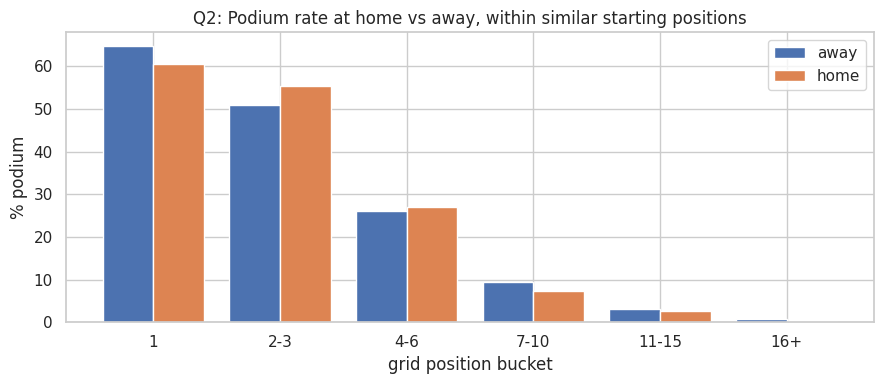

In [36]:
import statsmodels.formula.api as smf

def home_effect(df, label):
    m = smf.logit("podium ~ home + C(grid_bucket)", data=df).fit(disp=0)
    ci = np.exp(m.conf_int().loc["home"])
    print(f"{label:12s} odds ratio for home = {np.exp(m.params['home']):.2f} "
          f"(95% CI {ci[0]:.2f}–{ci[1]:.2f}), p = {m.pvalues['home']:.3f}, rows = {len(df)}")

home_effect(h, "All years")
home_effect(h[h["year"] >= 2003], "2003+")      # robustness check on the modern era

x = np.arange(len(q2))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, q2["away_rate"] * 100, width=0.4, label="away")
plt.bar(x + 0.2, q2["home_rate"] * 100, width=0.4, label="home")
plt.xticks(x, q2.index); plt.xlabel("grid position bucket"); plt.ylabel("% podium")
plt.title("Q2: Podium rate at home vs away, within similar starting positions")
plt.legend(); plt.tight_layout(); plt.show()

In [37]:
# Car-component failures (matched as text inside the status, case-insensitive)
MECH_PATTERNS = [
    "engine", "gearbox", "transmission", "clutch", "hydraulic", "electric", "radiator", "suspension",
    "brake", "differential", "overheat", "mechanical", "power unit", "turbo", "fuel", "oil", "water",
    "throttle", "steering", "exhaust", "driveshaft", "halfshaft", "axle", "battery", r"\bers\b",
    "power loss", "vibration", "spark", "pneumatic", "cooling", "pump", "injection", "ignition",
    "alternator", "magneto", "crankshaft", "piston", "valve", "wheel bearing", "drivetrain",
    "technical", "distributor", "launch control",
]
# Not a component failure: crash, driver, regulation, or unclear cause. These override the list above.
EXCLUDE_PATTERNS = [
    "driver", "collision", "accident", "spun", "disqualified", "excluded", "damage", "debris",
    "puncture", "tyre", "wheel nut", "out of fuel", "fuel rig", "illness", "injur", "withdrew",
    "did not", "underweight", "safety", "physical", "fatal", "not classified", "retired", "handling",
]

st = clean["status"].copy()
s = st["status"].str.lower()
st["mechanical"] = (s.str.contains("|".join(MECH_PATTERNS), regex=True)
                    & ~s.str.contains("|".join(EXCLUDE_PATTERNS), regex=True))

cons = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
r3 = (base[base["year"] >= 2014]
      .merge(st, on="statusId")
      .merge(cons, on="constructorId"))
r3["period"] = np.where(r3["year"] <= 2021, "2014-2021", "2022-2024")

# Review table: every non-finish status in 2014–2024 and how we labelled it
not_finished = ~(r3["status"].eq("Finished") | r3["status"].str.startswith("+"))
review = (r3[not_finished].groupby(["mechanical", "status"]).size().rename("count")
            .reset_index().sort_values(["mechanical", "count"], ascending=[False, False]))
display(review)

,mechanical,status,count
31,True,Engine,80
23,True,Brakes,48
36,True,Gearbox,42
42,True,Power Unit,42
47,True,Suspension,25
37,True,Hydraulics,15
30,True,Electrical,14
43,True,Power loss,13
39,True,Oil leak,10
41,True,Overheating,8


Overall mechanical-retirement rate per period:
period
2014-2021    9.0%
2022-2024    5.6%
Name: mechanical, dtype: object 



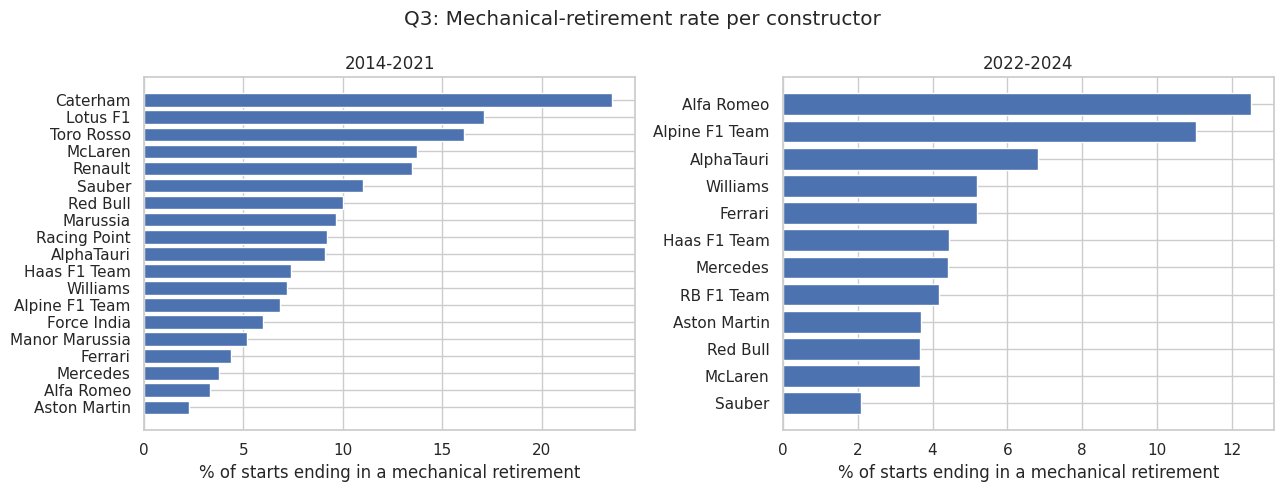


Top 5, 2014-2021:


period,constructor,starts,mech_dnf,rate
2014-2021,Caterham,34,8,23.5%
2014-2021,Lotus F1,76,13,17.1%
2014-2021,Toro Rosso,242,39,16.1%
2014-2021,McLaren,320,44,13.8%
2014-2021,Renault,200,27,13.5%



Top 5, 2022-2024:


period,constructor,starts,mech_dnf,rate
2022-2024,Alfa Romeo,88,11,12.5%
2022-2024,Alpine F1 Team,136,15,11.0%
2022-2024,AlphaTauri,88,6,6.8%
2022-2024,Ferrari,135,7,5.2%
2022-2024,Williams,135,7,5.2%


In [38]:
MIN_STARTS_Q3 = 20   # ≈ half a season for a 2-car team, so tiny samples can't top the list

rates = (r3.groupby(["period", "constructor"])
           .agg(starts=("mechanical", "size"), mech_dnf=("mechanical", "sum")))
rates["rate"] = rates["mech_dnf"] / rates["starts"]
rates = rates[rates["starts"] >= MIN_STARTS_Q3].reset_index()

print("Overall mechanical-retirement rate per period:")
print((r3.groupby("period")["mechanical"].mean() * 100).round(1).astype(str) + "%", "\n")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    d = rates[rates["period"] == period].sort_values("rate")
    ax.barh(d["constructor"], d["rate"] * 100)
    ax.set_title(f"{period}"); ax.set_xlabel("% of starts ending in a mechanical retirement")
fig.suptitle("Q3: Mechanical-retirement rate per constructor"); plt.tight_layout(); plt.show()

for period in ["2014-2021", "2022-2024"]:
    print(f"\nTop 5, {period}:")
    display(rates[rates["period"] == period].nlargest(5, "rate")
            .style.format({"rate": "{:.1%}"}).hide(axis="index"))

## 8. Feature engineering & selection
Every feature must be (a) known before the race, (b) justified with a plot or statistic.

Candidate groups: **grid**, **qualifying** (position, gap to pole), **driver form** (past races only),
**constructor form** (past races only), **standings before this race** (shifted by one race).

In [39]:
# ===== 8.1 Chronological order + previous race in the same season =====
races_o = clean["races"][["raceId", "year", "round"]].sort_values(["year", "round"]).copy()
races_o["prev_raceId"] = races_o.groupby("year")["raceId"].shift(1).astype("Int64")
races_o["race_seq"] = np.arange(len(races_o))

df = (base.merge(races_o[["raceId", "prev_raceId", "race_seq"]], on="raceId")
          .sort_values(["race_seq", "grid"]).reset_index(drop=True))

# ===== 8.2 Grid features =====
df["field_size"] = df.groupby("raceId")["driverId"].transform("size")
df["grid_rel"]   = df["grid"] / df["field_size"]
df["front_row"]  = (df["grid"] <= 2).astype(int)

# ===== 8.3 Qualifying features =====
q = clean["qualifying"][["raceId", "driverId", "position", "q1_s", "q2_s", "q3_s"]].rename(columns={"position": "quali_pos"})
q["best_q_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
pole_time = q.groupby("raceId")["best_q_s"].transform("min")
q["gap_to_pole_pct"] = (q["best_q_s"] - pole_time) / pole_time * 100
df = df.merge(q[["raceId", "driverId", "quali_pos", "gap_to_pole_pct"]], on=["raceId", "driverId"], how="left")
df["has_quali"]        = df["quali_pos"].notna().astype(int)
df["grid_minus_quali"] = df["grid"] - df["quali_pos"]

# ===== 8.4 Form features (PAST races only: shift(1) excludes the current race) =====
df = df.sort_values(["race_seq", "grid"]).reset_index(drop=True)
g = df.groupby("driverId")
df["drv_races_before"]      = g.cumcount()
df["drv_podium_rate_last5"] = g["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df["drv_avg_finish_last5"]  = g["positionOrder"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

df = df.merge(st[["statusId", "mechanical"]], on="statusId", how="left")
team_race = (df.groupby(["constructorId", "raceId", "race_seq"], as_index=False)
               .agg(team_podiums=("podium", "sum"), team_best=("positionOrder", "min"),
                    team_mech=("mechanical", "sum"), team_starts=("mechanical", "size"))
               .sort_values("race_seq"))
tg = team_race.groupby("constructorId")
team_race["team_podiums_last5"]     = tg["team_podiums"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())
team_race["team_best_finish_last5"] = tg["team_best"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
mech_sum   = tg["team_mech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
starts_sum = tg["team_starts"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
team_race["team_mech_rate_last10"]  = mech_sum / starts_sum
df = df.merge(team_race[["constructorId", "raceId", "team_podiums_last5", "team_best_finish_last5",
                         "team_mech_rate_last10"]], on=["constructorId", "raceId"], how="left")

# ===== 8.5 Championship standings BEFORE the race (= standings after the previous round) =====
ds = clean["driver_standings"][["raceId", "driverId", "points", "wins"]].rename(
        columns={"raceId": "prev_raceId", "points": "drv_pts_before", "wins": "drv_wins_before"})
ds["prev_raceId"] = ds["prev_raceId"].astype("Int64")
ds["leader"] = ds.groupby("prev_raceId")["drv_pts_before"].transform("max")
ds["drv_pts_share"] = np.where(ds["leader"] > 0, ds["drv_pts_before"] / ds["leader"], 0.0)

cs = clean["constructor_standings"][["raceId", "constructorId", "points", "wins"]].rename(
        columns={"raceId": "prev_raceId", "points": "con_pts_before", "wins": "con_wins_before"})
cs["prev_raceId"] = cs["prev_raceId"].astype("Int64")
cs["leader"] = cs.groupby("prev_raceId")["con_pts_before"].transform("max")
cs["con_pts_share"] = np.where(cs["leader"] > 0, cs["con_pts_before"] / cs["leader"], 0.0)

df = (df.merge(ds[["prev_raceId", "driverId", "drv_pts_share", "drv_wins_before"]], on=["prev_raceId", "driverId"], how="left")
        .merge(cs[["prev_raceId", "constructorId", "con_pts_share", "con_wins_before"]], on=["prev_raceId", "constructorId"], how="left"))
# Round 1, or no standings entry yet = 0 points and 0 wins so far this season (true, not a guess)
for c in ["drv_pts_share", "drv_wins_before", "con_pts_share", "con_wins_before"]:
    df[c] = df[c].fillna(0)

# ===== 8.6 Home race (mapping from Q2) =====
df = (df.merge(drv[["driverId", "home_country"]], on="driverId", how="left")
        .merge(circ_c[["circuitId", "circuit_country"]], on="circuitId", how="left"))
df["is_home"] = (df["home_country"] == df["circuit_country"]).astype(int)

In [40]:
# ===== 8.7 Assemble the modeling table + leakage checks =====
FEATURE_GROUPS = {
    "grid":             ["grid", "grid_rel", "front_row", "pit_lane_start", "field_size"],
    "qualifying":       ["quali_pos", "gap_to_pole_pct", "grid_minus_quali", "has_quali"],
    "driver_form":      ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_before"],
    "constructor_form": ["team_podiums_last5", "team_best_finish_last5", "team_mech_rate_last10"],
    "standings":        ["drv_pts_share", "drv_wins_before", "con_pts_share", "con_wins_before"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
ID_COLS  = ["raceId", "driverId", "constructorId", "year", "round", "date"]

model_df = df[ID_COLS + FEATURES + ["podium"]].copy()

# Check 1: no post-race column is used as a feature
POST_RACE = ["positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
             "fastestLap", "rank", "fastestLapTime", "fastestLapTime_s", "fastestLapSpeed", "statusId", "mechanical"]
assert not set(FEATURES) & set(POST_RACE), "post-race column used as a feature!"

# Check 2: one row per driver per race
assert not model_df.duplicated(["raceId", "driverId"]).any()

# Check 3: a driver's first race has no form (nothing in the past to compute it from)
assert df.loc[df["drv_races_before"] == 0, "drv_podium_rate_last5"].isna().all()

# Check 4: recompute the form feature by hand for random rows, using ONLY earlier races
rng = np.random.default_rng(SEED)
for i in rng.choice(df.index[df["drv_races_before"] >= 5], size=20, replace=False):
    row  = df.loc[i]
    past = df[(df["driverId"] == row["driverId"]) & (df["race_seq"] < row["race_seq"])].nlargest(5, "race_seq")
    assert np.isclose(past["podium"].mean(), row["drv_podium_rate_last5"]), f"form mismatch at row {i}"
print("Leakage checks passed ✅")

# Same two training-year versions as before, now with features
model_tables = {name: model_df[model_df["year"] >= start].copy() for name, start in YEAR_OPTIONS.items()}
print(f"model_df: {model_df.shape[0]} rows × {len(FEATURES)} features")

# Missing values per feature in the 2003+ version
miss = model_tables["from_2003"][FEATURES].isna().mean().mul(100).round(1)
display(miss[miss > 0].rename("% missing (2003+)").to_frame())

Leakage checks passed ✅
model_df: 24724 rows × 19 features


,% missing (2003+)
quali_pos,0.2
gap_to_pole_pct,1.6
grid_minus_quali,0.2
drv_podium_rate_last5,1.0
drv_avg_finish_last5,1.0
team_podiums_last5,0.5
team_best_finish_last5,0.5
team_mech_rate_last10,0.5


,spearman_with_podium,group
front_row,+0.53,grid
drv_podium_rate_last5,+0.53,driver_form
team_podiums_last5,+0.51,constructor_form
con_wins_before,+0.50,standings
quali_pos,-0.50,qualifying
grid,-0.49,grid
grid_rel,-0.49,grid
gap_to_pole_pct,-0.48,qualifying
drv_wins_before,+0.47,standings
team_best_finish_last5,-0.47,constructor_form


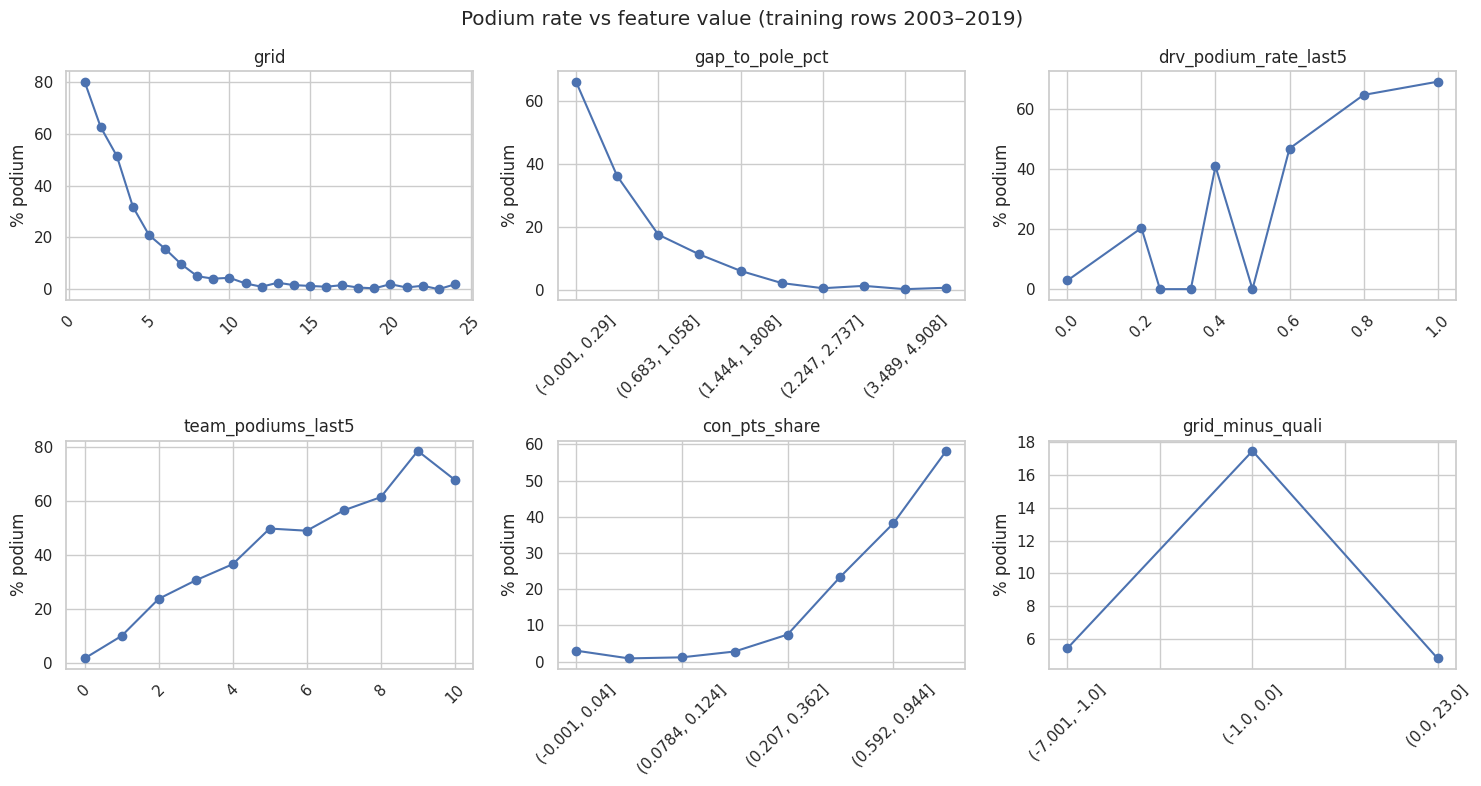

In [41]:
# ===== 8.8 Evidence for each feature (TRAINING years only, so validation/test stay unseen) =====
ev = model_tables["from_2003"]
ev = ev[ev["year"] <= TRAIN_END]

corr = (ev[FEATURES].corrwith(ev["podium"], method="spearman")
          .rename("spearman_with_podium").to_frame())
corr["group"] = [g for g, cols in FEATURE_GROUPS.items() for _ in cols]
display(corr.sort_values("spearman_with_podium", key=abs, ascending=False)
            .style.format({"spearman_with_podium": "{:+.2f}"}))

PLOT_FEATURES = ["grid", "gap_to_pole_pct", "drv_podium_rate_last5",
                 "team_podiums_last5", "con_pts_share", "grid_minus_quali"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), PLOT_FEATURES):
    x = ev[f]
    bins = x if x.nunique() <= 25 else pd.qcut(x, 10, duplicates="drop")
    rate = ev.groupby(bins, observed=True)["podium"].mean() * 100
    rate.plot(ax=ax, marker="o")
    ax.set_title(f); ax.set_ylabel("% podium"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Podium rate vs feature value (training rows 2003–2019)")
plt.tight_layout(); plt.show()

**Feature evidence (training rows 2003–2019 only, so validation and test stay unseen):**
- **Leakage-safe:** all form features use only earlier races (`shift(1)` before rolling); standings come from the previous round.
  Verified by recomputing the form feature by hand for 20 random rows using only earlier races.
- **Missing values are small and explained:** ≤ 1.6% per feature (no qualifying lap time, a driver's or team's first race).
  They are left as `NaN` here and imputed inside the model pipeline, fitted on the training set only.
- **Strong predictors (|Spearman| 0.43–0.53):** grid / front row, qualifying position and gap to pole, driver and team recent form,
  championship standings. The plots show the expected direction: podium rate falls steeply with grid position and gap to pole,
  and rises with recent form and team points.
- **`front_row` (+0.53) correlates more strongly than `grid` (−0.49)** because the relationship is non-linear: podium chances
  drop sharply after the first few grid slots.
- **Overlap:** grid, qualifying, form and standings all partly measure car performance, so their individual contributions are
  tested with an ablation in Section 11 rather than assumed from these correlations.
- **Weak features kept for now:** `pit_lane_start` and `grid_minus_quali` describe rare situations (penalties, pit-lane starts),
  so a low overall correlation does not rule them out; `has_quali` is near-constant from 2003 but needed for the all-years option.
  The ablation decides whether they stay.
- **Excluded:** `is_home` (see Q2).

## 9. Train / validation / test split
Time-based: train ≤ 2019, validation 2020–2021, test ≥ 2022.

In [42]:
# ===== 9. Time-based split =====
def time_split(d):
    train = d[d["year"] <= TRAIN_END]
    val   = d[d["year"].between(*VAL_YEARS)]
    test  = d[d["year"] >= TEST_START]
    return train, val, test

splits = {name: time_split(t) for name, t in model_tables.items()}

# Sanity checks: no race in two sets, and the sets follow each other in time
for name, (tr, va, te) in splits.items():
    assert not (set(tr["raceId"]) & set(va["raceId"])) and not (set(va["raceId"]) & set(te["raceId"]))
    assert tr["date"].max() < va["date"].min() and va["date"].max() < te["date"].min()

summary = pd.DataFrame([
    {"option": name, "set": s, "years": f"{d['year'].min()}–{d['year'].max()}",
     "races": d["raceId"].nunique(), "rows": len(d), "podium_rate": f"{d['podium'].mean():.1%}"}
    for name, (tr, va, te) in splits.items()
    for s, d in [("train", tr), ("validation", va), ("test", te)]
])
display(summary)

,option,set,years,races,rows,podium_rate
0,from_2003,train,2003–2019,321,6821,14.1%
1,from_2003,validation,2020–2021,39,779,15.0%
2,from_2003,test,2022–2024,68,1356,15.0%
3,all_years,train,1950–2019,1007,22589,13.4%
4,all_years,validation,2020–2021,39,779,15.0%
5,all_years,test,2022–2024,68,1356,15.0%


## 9. Train / validation / test split

| Set | Seasons | Role |
|---|---|---|
| Train | ≤ 2019 (from 2003 or from 1950, see decision 1) | Fit the models |
| Validation | 2020–2021 | Choose hyperparameters, decision threshold, training-year option and feature set |
| Test | 2022–2024 | Final evaluation, used **once** at the end |

**Why a time-based split instead of a random split:**
- **It mirrors real use.** The model's job is to predict future races from past ones. A random split would let the model
  train on 2023 races and be tested on 2018, i.e. learn from the future.
- **It keeps each race in one set.** With a random split, teammates from the same race could land in train and test,
  and the model would learn that specific race's conditions instead of general patterns.
- **The form and standings features are built in time order.** A time split keeps that order intact for evaluation.

**Why these years:**
- **Test from 2022:** the 2022 regulation change (ground-effect cars) reshuffled the competitive order,
  so the test asks a realistic and difficult question: does the model still work after a rule change?
- **Validation 2020–2021:** the two seasons directly before the test, the closest "rehearsal" for it.
- **Caveat:** validation is still in the hybrid era (2014–2021), so a model tuned on it may be optimistic about the new era,
  and 2020 was a shortened COVID season with some unusual circuits.

Checks passed: no race appears in more than one set, and the sets do not overlap in time.

## 10. Models
Baseline → ≥ 2 statistical models → shallow NN. Report ROC-AUC, PR-AUC, F1 on train/val/test. Thresholds chosen on validation only.

In [ ]:
# ===== 10.1 Shared setup: data, preprocessing, metrics =====
import copy, warnings
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, log_loss)

TABLE = "from_2003"                        # changed only in the training-years experiment
train_df, val_df, test_df = splits[TABLE]
X_tr, y_tr = train_df[FEATURES], train_df["podium"]
X_va, y_va = val_df[FEATURES],   val_df["podium"]
X_te, y_te = test_df[FEATURES],  test_df["podium"]

def make_pipeline(model):
    """Same preprocessing for every model: fill gaps with the TRAINING median, then standardise."""
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale",  StandardScaler()),
                     ("model",  model)])

THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)

def best_threshold(y, p):
    """Threshold that maximises F1 on the given (validation) data."""
    f1s = [f1_score(y, p >= t, zero_division=0) for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(f1s))])

def all_metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat, zero_division=0),
            "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat, zero_division=0)}

results = []       # one row per (attempt, split); test rows are added only at the very end
fitted  = {}       # attempt name -> (fitted pipeline, threshold)

def evaluate(name, pipe, X_train=None, y_train=None):
    """Fit on train, pick the threshold on validation, record train + validation metrics."""
    X_train = X_tr if X_train is None else X_train
    y_train = y_tr if y_train is None else y_train
    pipe.fit(X_train, y_train)
    p_tr, p_va = pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_va)[:, 1]
    thr = best_threshold(y_va, p_va)
    for split_name, y, p in [("train", y_train, p_tr), ("validation", y_va, p_va)]:
        results.append({"attempt": name, "set": split_name, "threshold": thr, **all_metrics(y, p, thr)})
    fitted[name] = (pipe, thr)
    r = results[-1]
    print(f"{name:32s} val PR-AUC={r['PR-AUC']:.3f}  ROC-AUC={r['ROC-AUC']:.3f}  F1={r['F1']:.3f}  (thr={thr})")
    return pipe

print(f"Train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape}")

In [ ]:
# ===== 10.2 Effect of preprocessing on the data (fitted on TRAIN only) =====
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_tr)
after = pd.DataFrame(prep.transform(X_tr), columns=FEATURES, index=X_tr.index)
effect = pd.DataFrame({
    "missing_before": X_tr.isna().sum(), "missing_after": after.isna().sum(),
    "mean_before": X_tr.mean(), "std_before": X_tr.std(),
    "mean_after": after.mean(), "std_after": after.std(),
    "min_before": X_tr.min(), "max_before": X_tr.max(),
}).round(2)
display(effect)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
X_tr[["grid", "gap_to_pole_pct", "drv_pts_share"]].plot(kind="box", ax=axes[0], title="Before: very different ranges")
after[["grid", "gap_to_pole_pct", "drv_pts_share"]].plot(kind="box", ax=axes[1], title="After: common scale (mean 0, std 1)")
plt.tight_layout(); plt.show()

In [ ]:
# ===== 10.3 Attempt 1 — BASELINE: logistic regression, default settings =====
evaluate("1. Baseline: LogReg (default)", make_pipeline(LogisticRegression(max_iter=1000)))

# ===== 10.4 Attempt 2 — Logistic regression, tuned regularisation (C) on validation =====
for C in [0.01, 0.1, 1, 10]:
    evaluate(f"2. LogReg C={C}", make_pipeline(LogisticRegression(C=C, max_iter=1000)))

In [ ]:
# ===== 10.5 Attempt 3 — Random forest, small hyperparameter search on validation =====
for depth in [4, 8, None]:
    for leaf in [5, 20]:
        evaluate(f"3. RF depth={depth} leaf={leaf}",
                 make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                                      n_jobs=-1, random_state=SEED)))

# ===== 10.6 Attempt 4 — Gradient boosting, small hyperparameter search on validation =====
for lr in [0.03, 0.1]:
    for leaves in [8, 31]:
        evaluate(f"4. GBM lr={lr} leaves={leaves}",
                 make_pipeline(HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves,
                                                              max_iter=300, random_state=SEED)))

In [ ]:
# ===== 10.7 Attempt 5 — Shallow neural network (1–2 hidden layers), trained epoch by epoch =====
# We train one epoch at a time and track the loss on train AND validation,
# then keep the epoch with the lowest validation loss (early stopping on validation, never on test).
prep_nn = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_tr)
Xtr_nn, Xva_nn = prep_nn.transform(X_tr), prep_nn.transform(X_va)

def train_mlp(hidden, alpha, epochs=150):
    mlp = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=0.001,
                        batch_size=128, random_state=SEED)
    hist, best, best_loss = [], None, np.inf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for epoch in range(epochs):
            mlp.partial_fit(Xtr_nn, y_tr, classes=[0, 1])
            tr_loss = log_loss(y_tr, mlp.predict_proba(Xtr_nn)[:, 1])
            va_loss = log_loss(y_va, mlp.predict_proba(Xva_nn)[:, 1])
            hist.append((tr_loss, va_loss))
            if va_loss < best_loss:
                best_loss, best, best_epoch = va_loss, copy.deepcopy(mlp), epoch + 1
    return best, best_epoch, np.array(hist)

nn_runs = {}
for hidden in [(32,), (64, 32)]:
    for alpha in [1e-4, 1e-2]:
        mlp, best_epoch, hist = train_mlp(hidden, alpha)
        name = f"5. NN {hidden} alpha={alpha}"
        nn_runs[name] = hist
        pipe = Pipeline([("impute", prep_nn.named_steps["impute"]), ("scale", prep_nn.named_steps["scale"]),
                         ("model", mlp)])
        # already trained: record metrics without refitting
        p_tr, p_va = pipe.predict_proba(X_tr)[:, 1], pipe.predict_proba(X_va)[:, 1]
        thr = best_threshold(y_va, p_va)
        for s, y, p in [("train", y_tr, p_tr), ("validation", y_va, p_va)]:
            results.append({"attempt": name, "set": s, "threshold": thr, **all_metrics(y, p, thr)})
        fitted[name] = (pipe, thr)
        r = results[-1]
        print(f"{name:32s} val PR-AUC={r['PR-AUC']:.3f}  ROC-AUC={r['ROC-AUC']:.3f}  F1={r['F1']:.3f}  "
              f"(thr={thr}, best epoch {best_epoch})")

# Learning curves (training performance over time)
fig, axes = plt.subplots(1, len(nn_runs), figsize=(4 * len(nn_runs), 3.5), sharey=True)
for ax, (name, hist) in zip(axes, nn_runs.items()):
    ax.plot(hist[:, 0], label="train"); ax.plot(hist[:, 1], label="validation")
    ax.set_title(name.replace("5. NN ", ""), fontsize=9); ax.set_xlabel("epoch")
axes[0].set_ylabel("log loss"); axes[0].legend()
fig.suptitle("Shallow NN learning curves"); plt.tight_layout(); plt.show()

In [ ]:
# ===== 10.8 Compare all attempts on VALIDATION and pick the best of each model family =====
res = pd.DataFrame(results)
val_res = res[res["set"] == "validation"].set_index("attempt")
display(val_res.drop(columns="set").sort_values("PR-AUC", ascending=False)
               .style.format("{:.3f}").background_gradient(subset=["PR-AUC"], cmap="Greens"))

family = val_res.index.str.extract(r"^(\d)\.", expand=False)
best_per_family = val_res.assign(family=family.values).groupby("family")["PR-AUC"].idxmax()
FINAL = ["1. Baseline: LogReg (default)"] + [best_per_family[f] for f in ["2", "3", "4", "5"]]
print("Selected on validation PR-AUC:", FINAL)

# Overfitting check: train vs validation for the selected models
gap = res[res["attempt"].isin(FINAL)].pivot(index="attempt", columns="set", values="PR-AUC").loc[FINAL]
gap["train − val"] = gap["train"] - gap["validation"]
display(gap.style.format("{:.3f}"))

In [ ]:
# ===== 10.10 FINAL: unseen test set (run once, after every choice above is fixed) =====
for name in FINAL:
    pipe, thr = fitted[name]
    p_te = pipe.predict_proba(X_te)[:, 1]
    results.append({"attempt": name, "set": "test", "threshold": thr, **all_metrics(y_te, p_te, thr)})

res = pd.DataFrame(results)
comparison = (res[res["attempt"].isin(FINAL) & res["set"].isin(["validation", "test"])]
                .set_index(["attempt", "set"])[["threshold", "ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]]
                .loc[FINAL])
display(comparison.style.format("{:.3f}"))

# ROC and precision-recall curves on the test set
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in FINAL:
    p_te = fitted[name][0].predict_proba(X_te)[:, 1]
    RocCurveDisplay.from_predictions(y_te, p_te, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_te, p_te, name=name, ax=axes[1])
axes[1].axhline(y_te.mean(), ls="--", c="grey", label="random (podium rate)")
axes[0].set_title("ROC curve (test)"); axes[1].set_title("Precision–recall curve (test)")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 11. Experiments
- Feature-group ablation
- ≥ 2 preprocessing-order experiments (e.g. scaler fit on train vs all; impute before vs after split)

## 12. Explainability
Global: permutation importance + SHAP. Local: LIME (+ SHAP waterfall). **Importance ≠ causation.**

## 13. Inference function
Demo on a complete record and a partially-missing record.

## 14. Limitations
- Qualifying-coverage drift
- Era sensitivity
- …